In [118]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [119]:
df=pd.read_csv("/content/healthcare_data_for_task.csv")

In [120]:
df.head()

,Patient_ID,Age,Gender,Blood_Type,Medical_Condition,Medical_Code,Date_of_Admission,Discharge_Date,Admission_Type,Billing_Amount
0,P0001,47,Male,AB+,Heart Disease,HEA004,2025-05-10,2025-05-16,Emergency,23218.31
1,P0002,62,Female,AB-,Diabetes,DIA001,2025-12-31,2026-01-02,Emergency,47010.56
2,P0003,36,Male,AB-,Heart Disease,HEA004,2025-11-10,2025-11-27,Emergency,39619.01
3,P0004,51,Male,A+,Heart Disease,HEA004,2023-05-02,2023-05-07,Elective,35963.71
4,P0005,30,Male,A+,Diabetes,DIA001,2024-04-11,2024-04-17,Urgent,64615.93


In [121]:
df.describe()

,Age,Billing_Amount
count,1000.000000,1000.000000
mean,51.888000,77117.515720
std,19.256954,41955.242269
min,18.000000,5568.160000
25%,35.750000,40318.785000
50%,52.000000,77293.900000
75%,69.000000,113089.267500
max,85.000000,149921.800000


In [122]:
df.shape

(1000, 10)

In [123]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Blood_Type', 'Medical_Condition',
       'Medical_Code', 'Date_of_Admission', 'Discharge_Date', 'Admission_Type',
       'Billing_Amount'],
      dtype='object')

In [124]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         1000 non-null   object 
 1   Age                1000 non-null   int64  
 2   Gender             1000 non-null   object 
 3   Blood_Type         1000 non-null   object 
 4   Medical_Condition  1000 non-null   object 
 5   Medical_Code       970 non-null    object 
 6   Date_of_Admission  1000 non-null   object 
 7   Discharge_Date     1000 non-null   object 
 8   Admission_Type     1000 non-null   object 
 9   Billing_Amount     1000 non-null   float64
dtypes: float64(1), int64(1), object(8)
memory usage: 78.3+ KB


In [125]:
df['Age']
df['Medical_Code']

,Medical_Code
0,HEA004
1,DIA001
2,HEA004
3,HEA004
4,DIA001
...,...
995,DIA001
996,DIA001
997,DIA001
998,DIA001


In [126]:
df.isnull().sum()

,0
Patient_ID,0
Age,0
Gender,0
Blood_Type,0
Medical_Condition,0
Medical_Code,30
Date_of_Admission,0
Discharge_Date,0
Admission_Type,0
Billing_Amount,0


In [127]:
df['Medical_Code']=df['Medical_Code'].fillna('Unknown')

In [128]:
df['Admission_Type']=(
    df['Admission_Type']
    .str.strip()
    .str.title()
)


In [129]:
df['Admission_Type'].unique()

array(['Emergency', 'Elective', 'Urgent'], dtype=object)

In [130]:
df['Admission_Type'].value_counts()

,count
Admission_Type,
Emergency,381
Elective,368
Urgent,251


In [131]:
df['Date_of_Admission']=pd.to_datetime(
    df['Date_of_Admission']
)

In [132]:
df['Discharge_Date']=pd.to_datetime(
    df['Discharge_Date']
)

In [133]:
df['Date_of_Admission'].dt.year

,Date_of_Admission
0,2025
1,2025
2,2025
3,2023
4,2024
...,...
995,2023
996,2025
997,2023
998,2023


In [134]:
df['Date_of_Admission'].dt.month


,Date_of_Admission
0,5
1,12
2,11
3,5
4,4
...,...
995,3
996,4
997,5
998,2


In [135]:
df['Date_of_Admission'].dt.date


,Date_of_Admission
0,2025-05-10
1,2025-12-31
2,2025-11-10
3,2023-05-02
4,2024-04-11
...,...
995,2023-03-16
996,2025-04-17
997,2023-05-08
998,2023-02-11


In [136]:
df['Stay_Days']=(
    df['Discharge_Date']
    -df['Date_of_Admission']
).dt.days


In [137]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Patient_ID         1000 non-null   object        
 1   Age                1000 non-null   int64         
 2   Gender             1000 non-null   object        
 3   Blood_Type         1000 non-null   object        
 4   Medical_Condition  1000 non-null   object        
 5   Medical_Code       1000 non-null   object        
 6   Date_of_Admission  1000 non-null   datetime64[ns]
 7   Discharge_Date     1000 non-null   datetime64[ns]
 8   Admission_Type     1000 non-null   object        
 9   Billing_Amount     1000 non-null   float64       
 10  Stay_Days          1000 non-null   int64         
dtypes: datetime64[ns](2), float64(1), int64(2), object(6)
memory usage: 86.1+ KB


<Axes: xlabel='Admission_Type'>

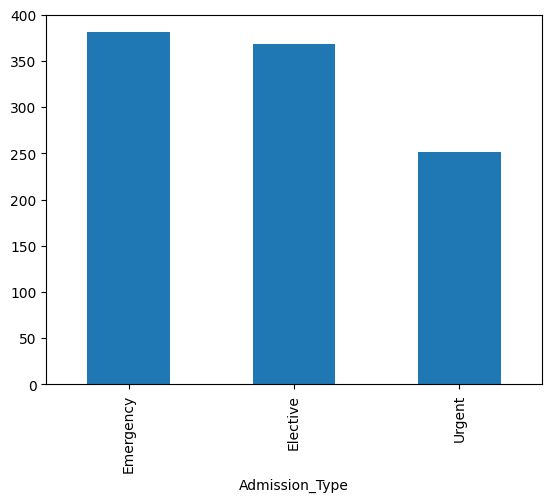

In [138]:
df['Admission_Type'].value_counts().plot(kind='bar')

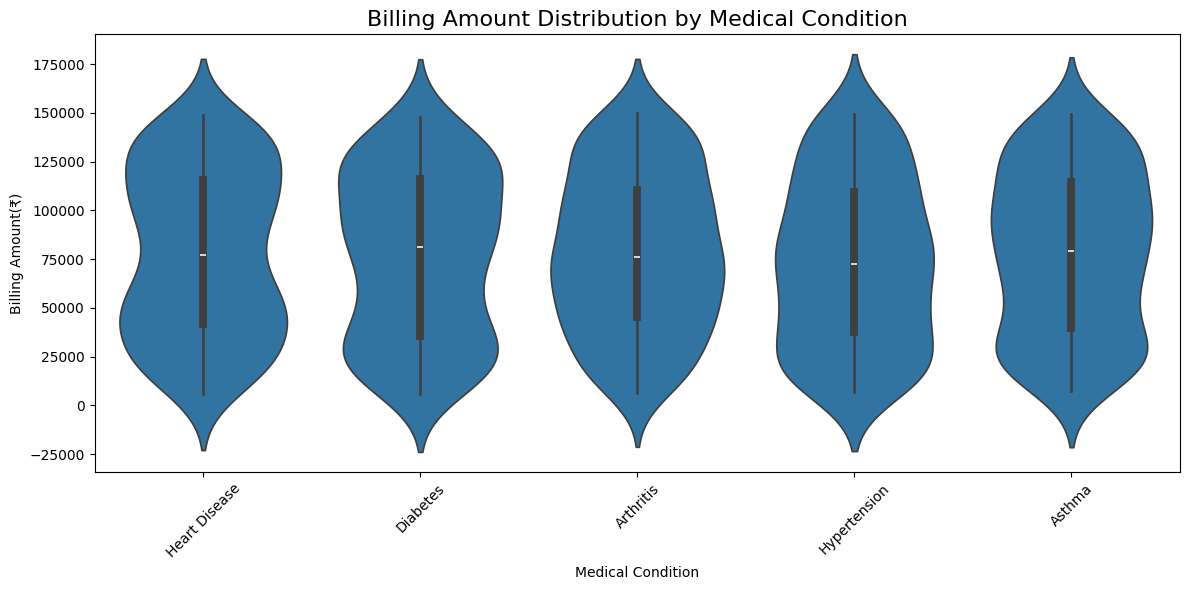

In [139]:
plt.figure(figsize=(12,6))

sns.violinplot(
    data=df,
    x='Medical_Condition',
    y='Billing_Amount'
)
plt.title('Billing Amount Distribution by Medical Condition',fontsize=16)
plt.xlabel('Medical Condition')
plt.ylabel('Billing Amount(₹)')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [140]:
numeric_df=df.select_dtypes(
    include="number"
)

In [141]:
corr=numeric_df.corr()
corr

,Age,Billing_Amount,Stay_Days
Age,1.000000,0.009515,0.019651
Billing_Amount,0.009515,1.000000,-0.040583
Stay_Days,0.019651,-0.040583,1.000000


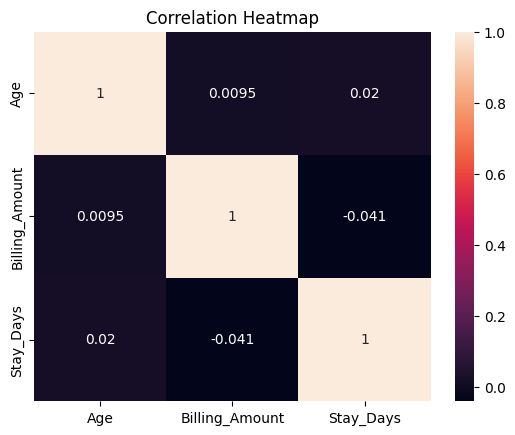

In [142]:
sns.heatmap(corr,annot=True)
plt.title("Correlation Heatmap")
plt.show()